# 1 Configuração e Implementação dos Módulos

In [11]:
import os
import sys
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Adiciona o diretório 'src' ao caminho do Python para importar os scripts do projeto
sys.path.append("../src")

from dataset import carregar_caminhos_dataset
from preprocessing import (
    aplicar_clahe,
    converter_para_cinza,
    preprocessar_imagem,
    remover_ruido,
)
from segmentation import (
    aplicar_morfologia,
    binarizar_otsu,
    extrair_maior_componente_e_roi,
)

print("Módulos e dependências carregados com sucesso!")

Módulos e dependências carregados com sucesso!


# 2: Mapeamento e Seleção de Amostras do Dataset

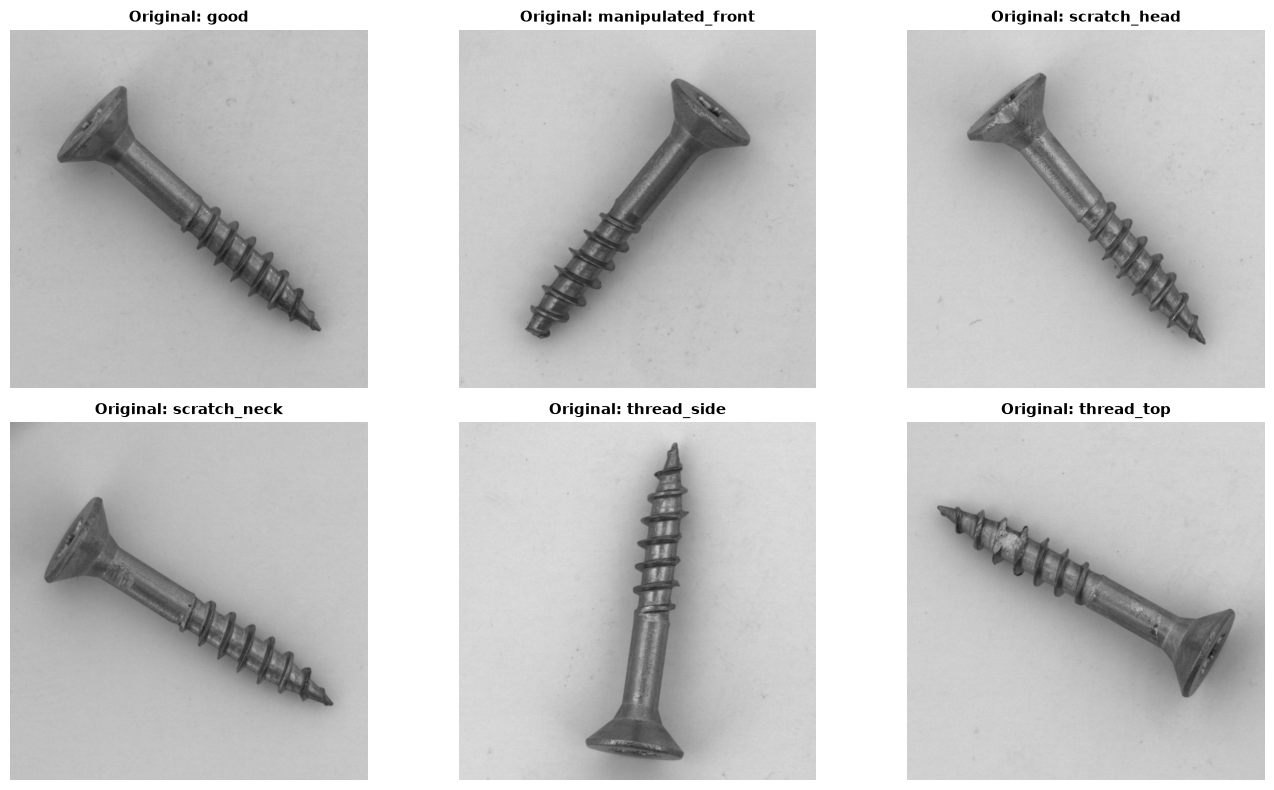

In [12]:
# Carrega a estrutura do dataset apontando para a pasta 'data' na raiz
df = carregar_caminhos_dataset(data_dir="../data")

# Lista das 6 categorias do conjunto de teste
categorias = [
    "good",
    "manipulated_front",
    "scratch_head",
    "scratch_neck",
    "thread_side",
    "thread_top",
]

# Seleciona a primeira imagem encontrada para cada categoria de teste
amostras = {}
for cat in categorias:
    df_cat = df[(df["split"] == "test") & (df["classe"] == cat)]
    if not df_cat.empty:
        amostras[cat] = df_cat.iloc[0]["caminho"]

# Exibe o grid com as imagens originais em RGB
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for i, (cat, caminho) in enumerate(amostras.items()):
    img_bgr = cv2.imread(caminho)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    axes[i].imshow(img_rgb)
    axes[i].set_title(f"Original: {cat}", fontsize=11, fontweight="bold")
    axes[i].axis("off")

plt.tight_layout()
plt.show()



# 3: Conversão para Escala de Cinza

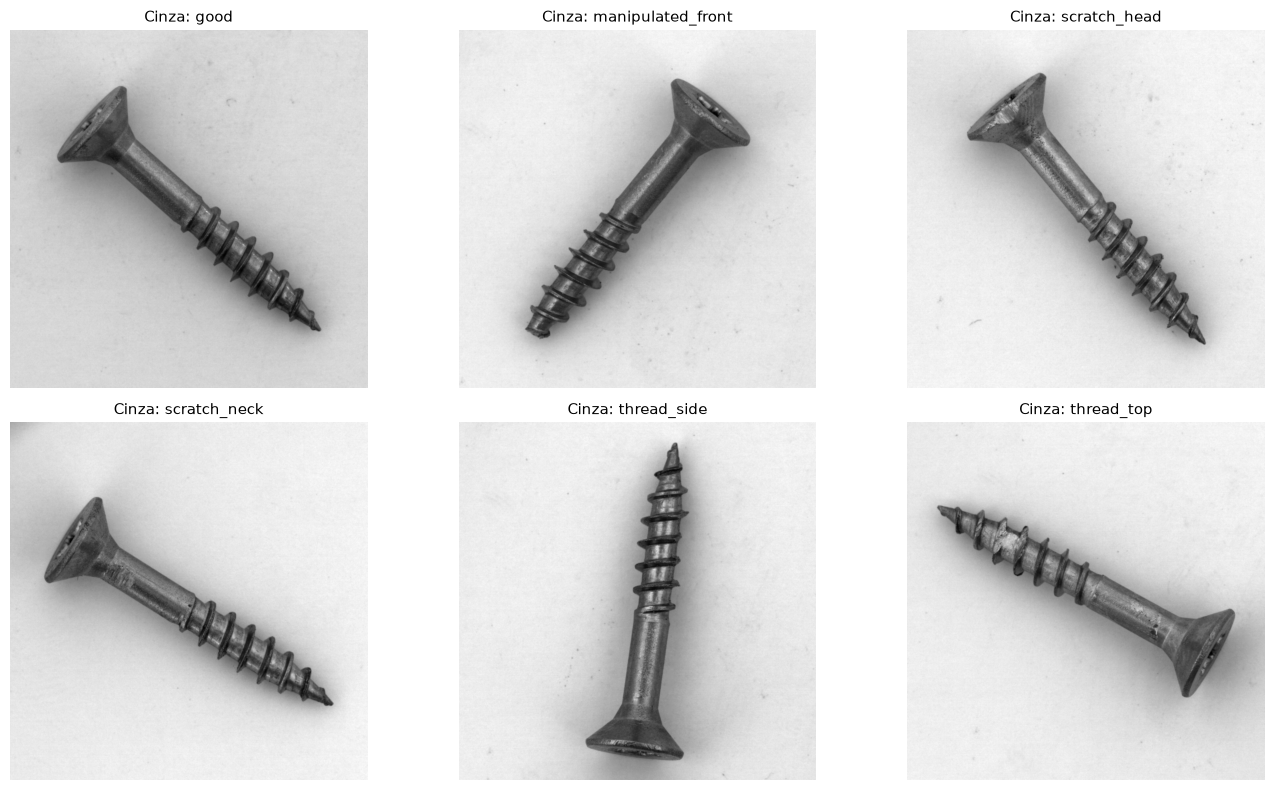

In [13]:
imgs_cinza = {}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for i, (cat, caminho) in enumerate(amostras.items()):
    img_bgr = cv2.imread(caminho)
    cinza = converter_para_cinza(img_bgr)
    imgs_cinza[cat] = cinza
    
    axes[i].imshow(cinza, cmap="gray")
    axes[i].set_title(f"Cinza: {cat}", fontsize=11)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


# 4: Equalização Adaptativa CLAHE

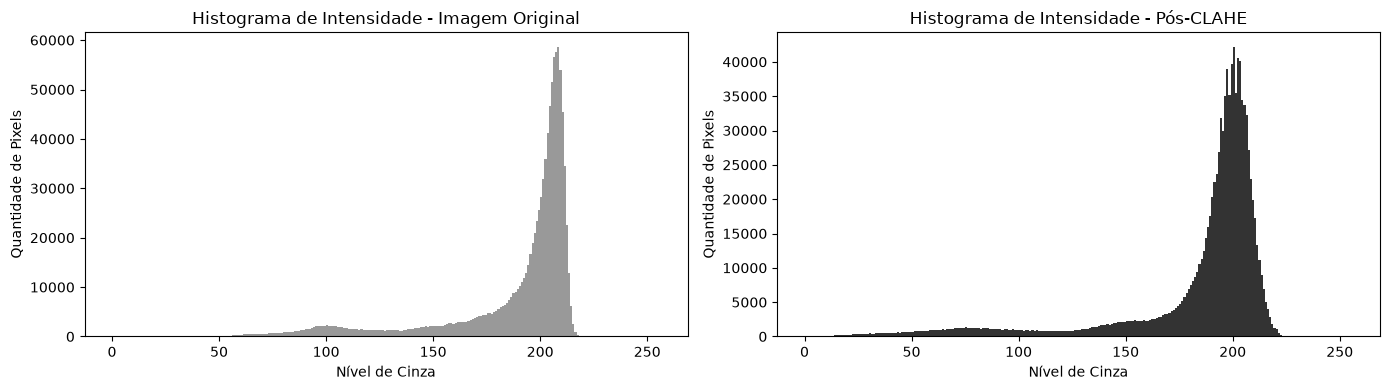

In [8]:
# Visualização do impacto da equalização adaptativa no histograma
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.hist(img_cinza.ravel(), bins=256, range=[0, 256], color="gray", alpha=0.8)
plt.title("Histograma de Intensidade - Imagem Original")
plt.xlabel("Nível de Cinza")
plt.ylabel("Quantidade de Pixels")

plt.subplot(1, 2, 2)
plt.hist(img_clahe.ravel(), bins=256, range=[0, 256], color="black", alpha=0.8)
plt.title("Histograma de Intensidade - Pós-CLAHE")
plt.xlabel("Nível de Cinza")
plt.ylabel("Quantidade de Pixels")

plt.tight_layout()
plt.show()


# 5: Grid Comparativo entre Todas as 6 Categorias de Teste

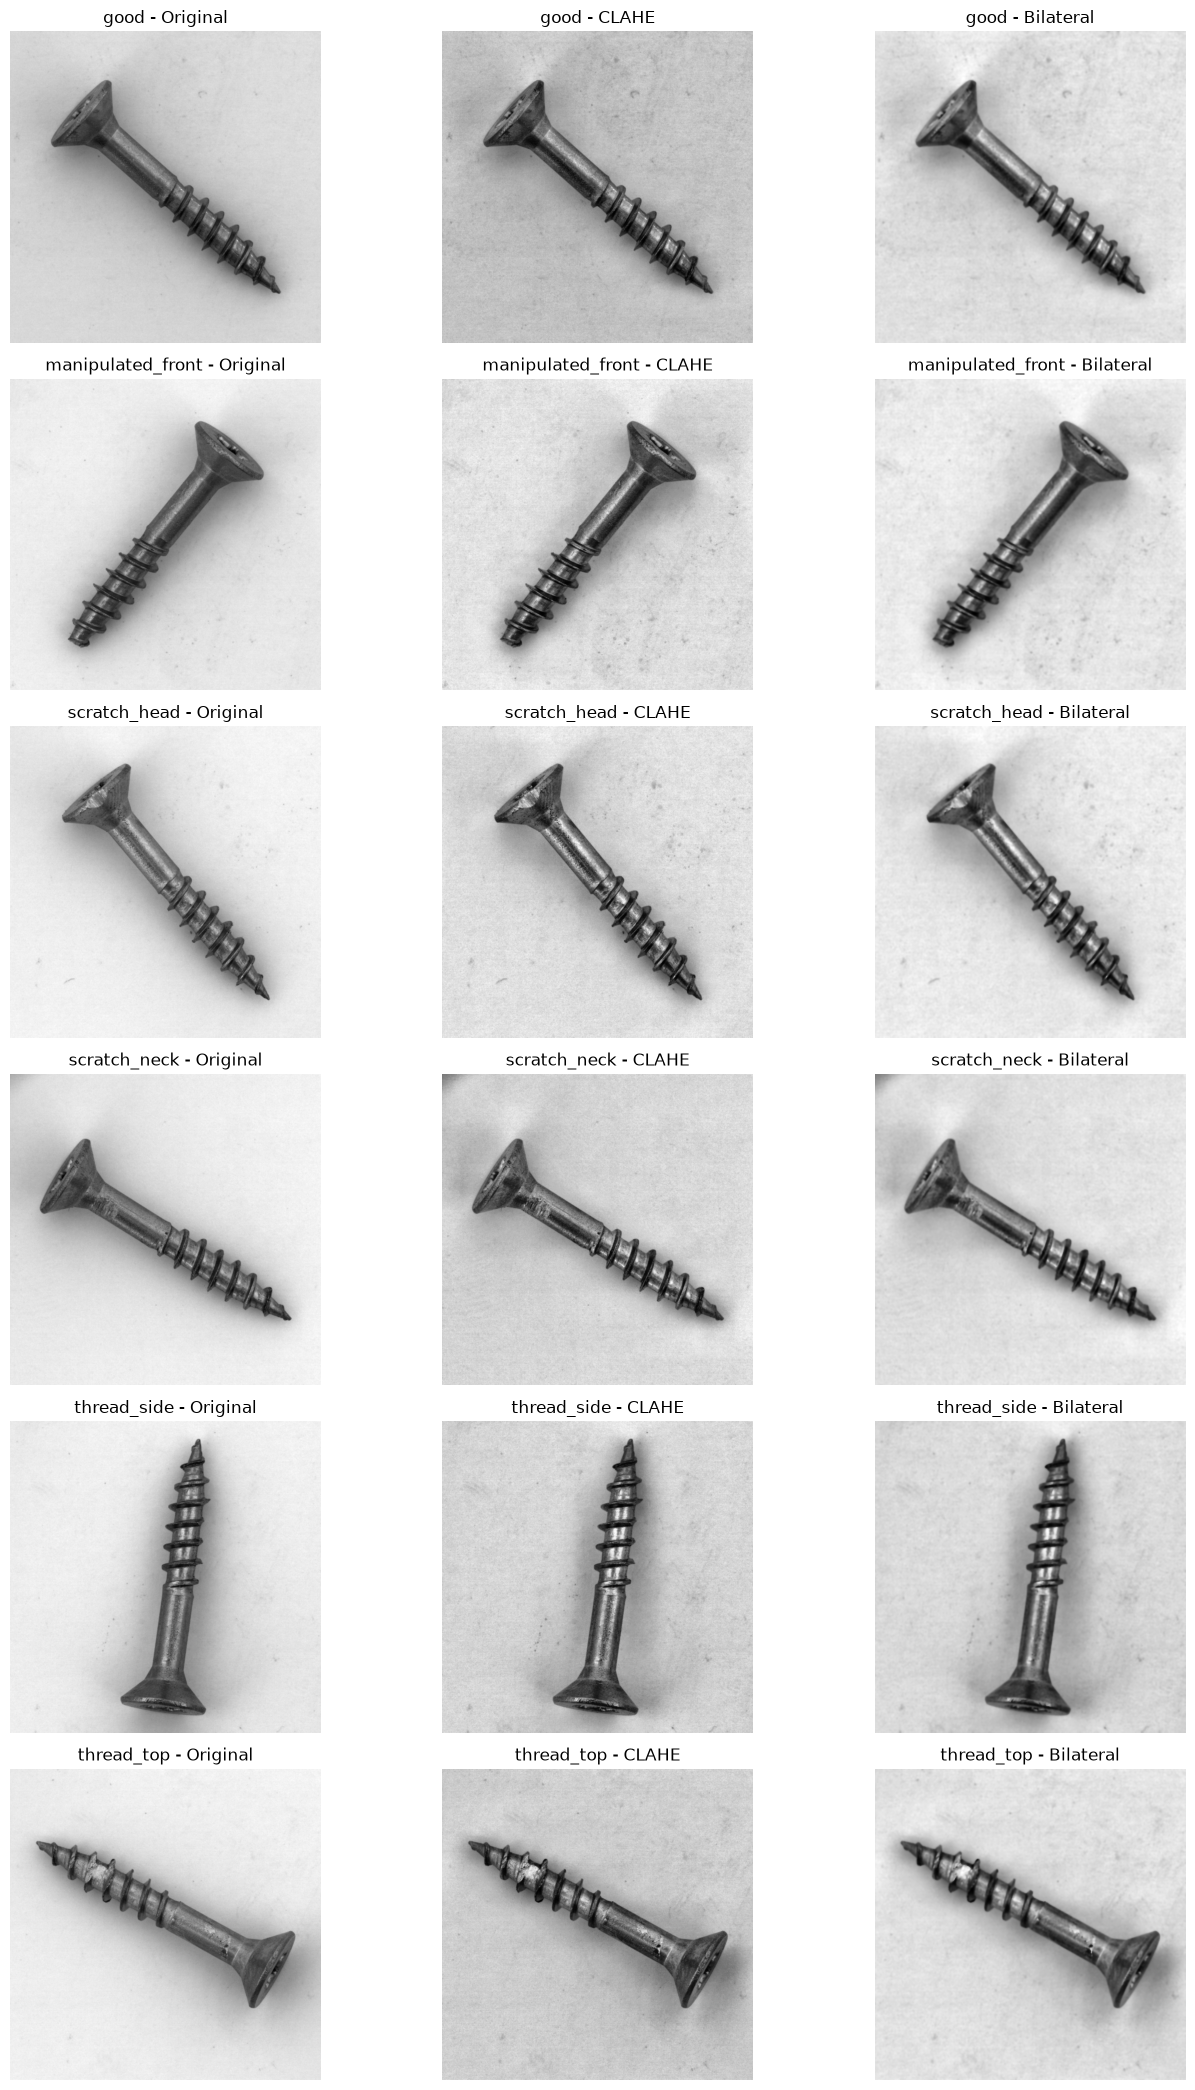

In [9]:
# Exibe o resultado do pré-processamento para cada uma das 6 categorias
fig, axes = plt.subplots(
    len(amostras_teste), 3, figsize=(14, 3.5 * len(amostras_teste))
)

for idx, (cat, caminho) in enumerate(amostras_teste.items()):
    img = cv2.imread(caminho)
    cinza = converter_para_cinza(img)
    clahe = aplicar_clahe(cinza, clip_limit=2.0)
    final = remover_ruido(clahe, metodo="bilateral")
    
    # Coluna 1: Imagem Original em Escala de Cinza
    axes[idx, 0].imshow(cinza, cmap="gray")
    axes[idx, 0].set_title(f"{cat} - Original")
    axes[idx, 0].axis("off")
    
    # Coluna 2: Após Equalização Adaptativa (CLAHE)
    axes[idx, 1].imshow(clahe, cmap="gray")
    axes[idx, 1].set_title(f"{cat} - CLAHE")
    axes[idx, 1].axis("off")
    
    # Coluna 3: Após Filtro Bilateral (Redução de Ruído)
    axes[idx, 2].imshow(final, cmap="gray")
    axes[idx, 2].set_title(f"{cat} - Bilateral")
    axes[idx, 2].axis("off")

plt.tight_layout()
plt.show()


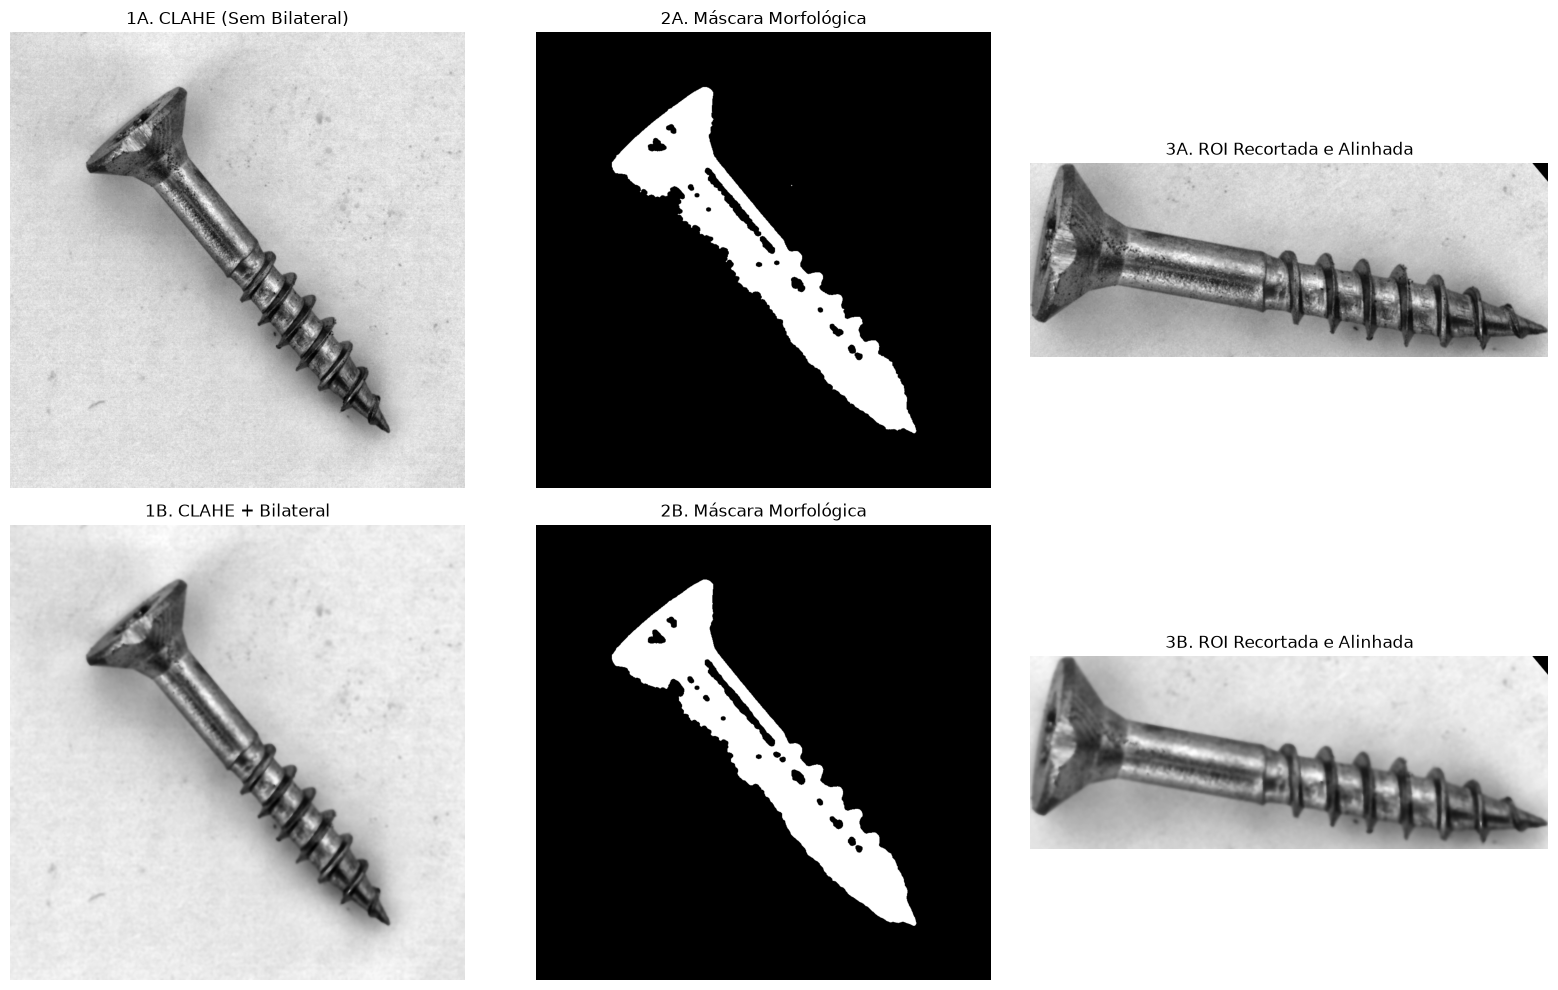

In [ ]:


# Carrega uma amostra do dataset
df = carregar_caminhos_dataset(data_dir="../data")
caminho_amostra = df[df["classe"] == "scratch_head"].iloc[0]["caminho"]
img_bgr = cv2.imread(caminho_amostra)
img_cinza = converter_para_cinza(img_bgr)

# --- CAMINHO A: Apenas CLAHE (Sem Filtro Bilateral) ---
img_clahe_sozinho = aplicar_clahe(img_cinza, clip_limit=2.0)
_, mask_otsu_a = binarizar_otsu(img_clahe_sozinho)
mask_limpa_a = aplicar_morfologia(mask_otsu_a)
roi_a, mask_roi_a, _ = extrair_maior_componente_e_roi(
    img_clahe_sozinho, mask_limpa_a, alinhar_eixo=True
)

# --- CAMINHO B: CLAHE + Filtro Bilateral ---
img_bilateral = remover_ruido(
    img_clahe_sozinho, metodo="bilateral", d=9, sigma_color=75, sigma_space=75
)
_, mask_otsu_b = binarizar_otsu(img_bilateral)
mask_limpa_b = aplicar_morfologia(mask_otsu_b)
roi_b, mask_roi_b, _ = extrair_maior_componente_e_roi(
    img_bilateral, mask_limpa_b, alinhar_eixo=True
)

# --- VISUALIZAÇÃO COMPARATIVA ---
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Linha 1: Sem Filtro Bilateral (Caminho A)
axes[0, 0].imshow(img_clahe_sozinho, cmap="gray")
axes[0, 0].set_title("1A. CLAHE (Sem Bilateral)")
axes[0, 0].axis("off")

axes[0, 1].imshow(mask_limpa_a, cmap="gray")
axes[0, 1].set_title("2A. Máscara Morfológica")
axes[0, 1].axis("off")

axes[0, 2].imshow(roi_a, cmap="gray")
axes[0, 2].set_title("3A. ROI Recortada e Alinhada")
axes[0, 2].axis("off")

# Linha 2: Com Filtro Bilateral (Caminho B)
axes[1, 0].imshow(img_bilateral, cmap="gray")
axes[1, 0].set_title("1B. CLAHE + Bilateral")
axes[1, 0].axis("off")

axes[1, 1].imshow(mask_limpa_b, cmap="gray")
axes[1, 1].set_title("2B. Máscara Morfológica")
axes[1, 1].axis("off")

axes[1, 2].imshow(roi_b, cmap="gray")
axes[1, 2].set_title("3B. ROI Recortada e Alinhada")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()
